In [6]:
# Mount Google Drive and load dataset from permanent location
# This avoids re-uploading the CSV every session

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML/Assignment-2/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [7]:
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling  

In [8]:
pd.set_option('display.max_columns', None)  # show all columns
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [9]:
'''TotalCharges supposed to be float64 like MonthlyCharges, but its of type object, so assumption is the column data may contain
   empty string'''
# Convert TotalCharges to numeric — blanks will become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Missing values after conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nTotalCharges dtype now:", df['TotalCharges'].dtype)

Missing values after conversion:
TotalCharges    11
dtype: int64

TotalCharges dtype now: float64


Class Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentage:
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


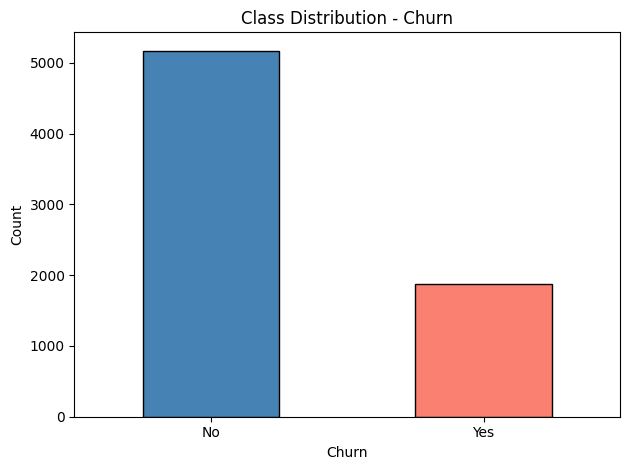

In [10]:
import matplotlib.pyplot as plt

print("Class Distribution:")
print(df['Churn'].value_counts())
print("\nPercentage:")
print(df['Churn'].value_counts(normalize=True).round(3) * 100)

# Plot
df['Churn'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'], edgecolor='black')
plt.title('Class Distribution - Churn')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Sub-step 1: Handle Missing Values
# TotalCharges had 11 blank spaces misread as strings — already converted to float64 above
# Using median instead of mean because billing data is right-skewed (outliers pull mean up)

median_val = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_val)

print("Missing values remaining:", df.isnull().sum().sum())
print(f"Filled with median value: {median_val:.2f}")

Missing values remaining: 0
Filled with median value: 1397.47


In [12]:
# Sub-step 2: Handle Duplicates
# Check for duplicate rows — same customer appearing more than once skews model training

before = len(df)
df.drop_duplicates(inplace=True)
after = len(df)

print(f"Rows before: {before}")
print(f"Rows after:  {after}")
print(f"Duplicates removed: {before - after}")

Rows before: 7043
Rows after:  7043
Duplicates removed: 0


In [13]:
# Sub-step 3: Drop customerID
# It is a unique identifier with no predictive value for ML models

df.drop(columns=['customerID'], inplace=True)

print("Columns remaining:", df.shape[1])
print(df.columns.tolist())

Columns remaining: 20
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [14]:
# Sub-step 4: Encode Categorical Features
# Binary columns → mapped to 0/1 directly
# Multi-category columns → Label Encoding (assigns a number to each category)

from sklearn.preprocessing import LabelEncoder

# Binary columns — simple mapping
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService',
               'PaperlessBilling', 'Churn']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0, 'Female': 0, 'Male': 1})

# Multi-category columns — Label Encoding
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
              'OnlineBackup', 'DeviceProtection', 'TechSupport',
              'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

le = LabelEncoder()
for col in multi_cols:
    df[col] = le.fit_transform(df[col])

print("Data types after encoding:")
print(df.dtypes)

Data types after encoding:
gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService       int64
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract              int64
PaperlessBilling      int64
PaymentMethod         int64
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


In [15]:
# Sub-step 5: Train-Test Split (80:20)
# stratify=y ensures both train and test sets maintain the same 73.5/26.5 class ratio
# random_state=42 ensures reproducibility — same split every time code is run

from sklearn.model_selection import train_test_split

X = df.drop('Churn', axis=1)  # Features
y = df['Churn']               # Target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Test set size:     {X_test.shape}")
print(f"\nClass distribution in training set:")
print(y_train.value_counts(normalize=True).round(3) * 100)
print(f"\nClass distribution in test set:")
print(y_test.value_counts(normalize=True).round(3) * 100)

Training set size: (5634, 19)
Test set size:     (1409, 19)

Class distribution in training set:
Churn
0    73.5
1    26.5
Name: proportion, dtype: float64

Class distribution in test set:
Churn
0    73.5
1    26.5
Name: proportion, dtype: float64


In [16]:
# Sub-step 6: Feature Scaling
# StandardScaler fitted ONLY on training data to prevent data leakage
# Same scaler then applied to test data (transform only, no refit)
# Only continuous columns need scaling — encoded binary columns are already 0/1

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)  # fit + transform on train
X_test_scaled  = scaler.transform(X_test)        # transform only on test

print("Scaling complete.")
print(f"Mean of tenure in training (should be ~0): {X_train_scaled[:, 4].mean():.4f}")
print(f"Std of tenure in training (should be ~1):  {X_train_scaled[:, 4].std():.4f}")

Scaling complete.
Mean of tenure in training (should be ~0): -0.0000
Std of tenure in training (should be ~1):  1.0000


In [17]:
# Model 1: Logistic Regression
# Uses scaled data since it is sensitive to feature magnitude
# max_iter=1000 to ensure convergence on this dataset
# random_state=42 for reproducibility

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"AUC       : {roc_auc_score(y_test, y_prob_lr):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_lr):.4f}")
print(f"MCC       : {matthews_corrcoef(y_test, y_pred_lr):.4f}")

=== Logistic Regression ===
Accuracy  : 0.7991
AUC       : 0.8403
Precision : 0.6426
Recall    : 0.5481
F1 Score  : 0.5916
MCC       : 0.4621


In [18]:
# Model 2: Decision Tree Classifier
# Uses unscaled data — Decision Trees are not sensitive to feature magnitude
# random_state=42 for reproducibility
# No max_depth set — tree grows fully, we'll observe overfitting tendency in metrics

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("=== Decision Tree ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"AUC       : {roc_auc_score(y_test, y_prob_dt):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_dt):.4f}")
print(f"MCC       : {matthews_corrcoef(y_test, y_pred_dt):.4f}")

=== Decision Tree ===
Accuracy  : 0.7303
AUC       : 0.6625
Precision : 0.4924
Recall    : 0.5187
F1 Score  : 0.5052
MCC       : 0.3202


In [19]:
# Model 3: K-Nearest Neighbor (kNN) Classifier
# Uses scaled data — kNN is distance-based, highly sensitive to feature magnitude
# n_neighbors=5 is the standard default starting point (k=5)

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

print("=== K-Nearest Neighbor ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"AUC       : {roc_auc_score(y_test, y_prob_knn):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_knn):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_knn):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_knn):.4f}")
print(f"MCC       : {matthews_corrcoef(y_test, y_pred_knn):.4f}")

=== K-Nearest Neighbor ===
Accuracy  : 0.7424
AUC       : 0.7605
Precision : 0.5151
Recall    : 0.5027
F1 Score  : 0.5088
MCC       : 0.3343


In [20]:
# Model 4: Naive Bayes (Gaussian)
# Uses unscaled data — Naive Bayes works with probabilities, not distances
# Gaussian variant chosen because our numeric features are roughly continuous
# Assumes all features are independent of each other (naive assumption)

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

print("=== Naive Bayes (Gaussian) ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"AUC       : {roc_auc_score(y_test, y_prob_nb):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_nb):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_nb):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_nb):.4f}")
print(f"MCC       : {matthews_corrcoef(y_test, y_pred_nb):.4f}")

=== Naive Bayes (Gaussian) ===
Accuracy  : 0.7452
AUC       : 0.8204
Precision : 0.5141
Recall    : 0.7326
F1 Score  : 0.6042
MCC       : 0.4392


In [21]:
# Model 5: Random Forest (Ensemble)
# Uses unscaled data — tree-based models are not sensitive to feature magnitude
# n_estimators=100 means 100 decision trees are built and their votes averaged
# Ensemble approach reduces overfitting seen in single Decision Tree
# random_state=42 for reproducibility

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("=== Random Forest ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"AUC       : {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_rf):.4f}")
print(f"MCC       : {matthews_corrcoef(y_test, y_pred_rf):.4f}")

=== Random Forest ===
Accuracy  : 0.7921
AUC       : 0.8225
Precision : 0.6373
Recall    : 0.5027
F1 Score  : 0.5620
MCC       : 0.4334


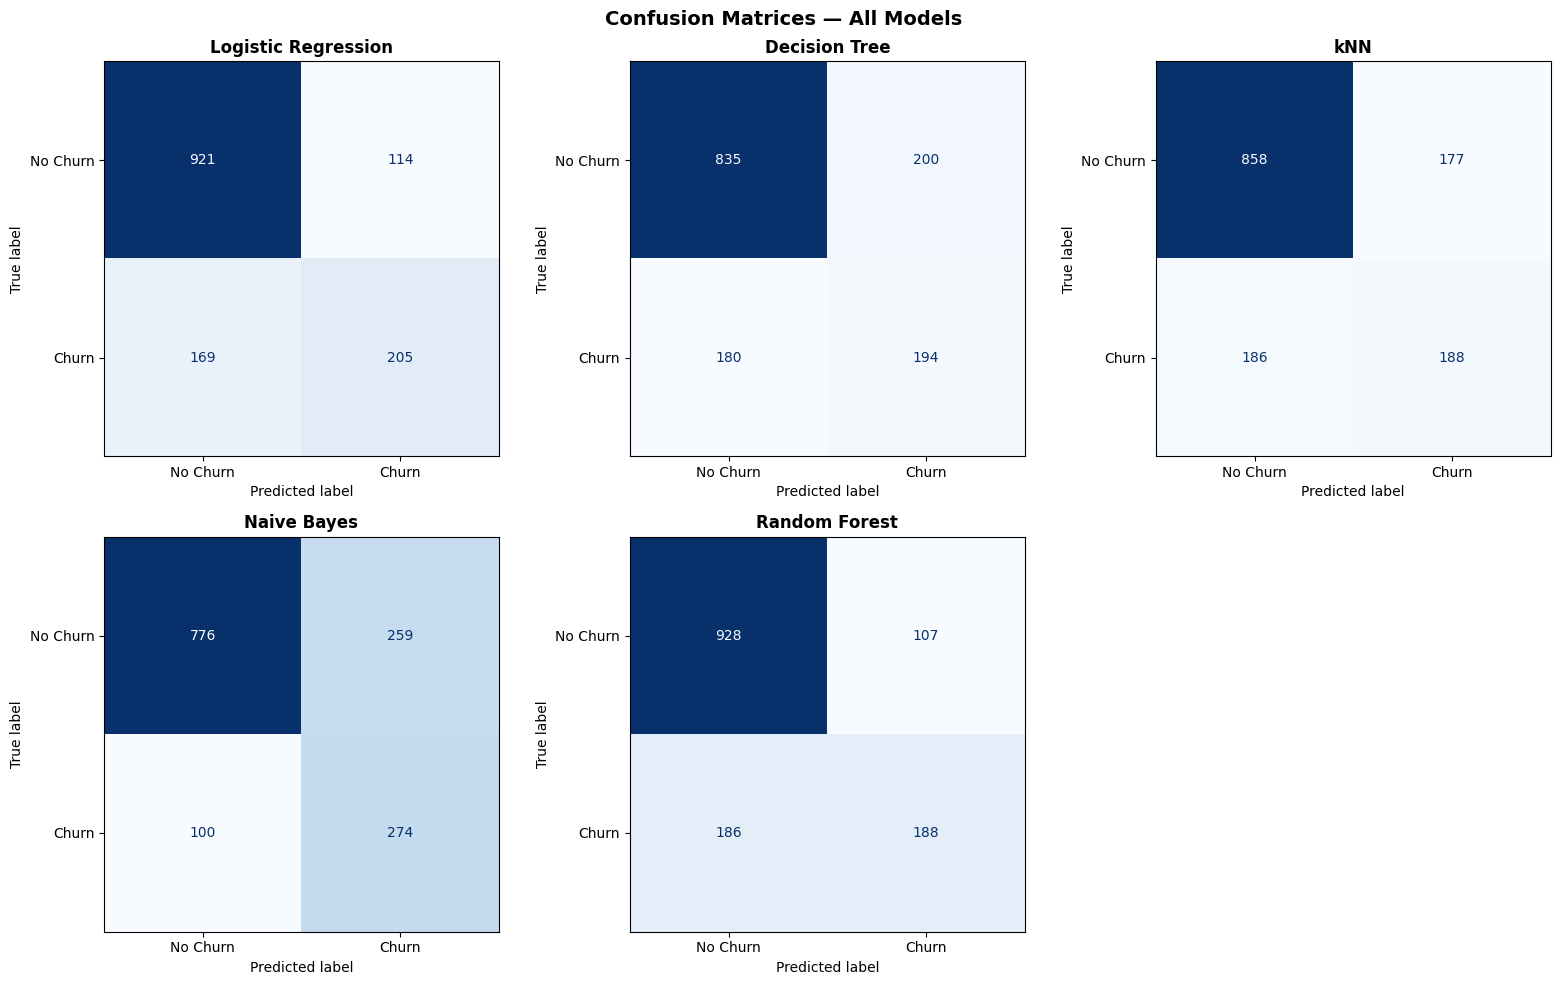

Saved as confusion_matrices.png


In [22]:
# Confusion Matrices for all 5 models
# Shows True Positives, False Positives, True Negatives, False Negatives
# Helps understand where each model makes mistakes

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

model_names = ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'Random Forest']
predictions = [y_pred_lr, y_pred_dt, y_pred_knn, y_pred_nb, y_pred_rf]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(zip(model_names, predictions)):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=axes[i], colorbar=False, cmap='Blues')
    axes[i].set_title(name, fontsize=12, fontweight='bold')

# Hide the 6th empty subplot
axes[5].set_visible(False)

plt.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved as confusion_matrices.png")

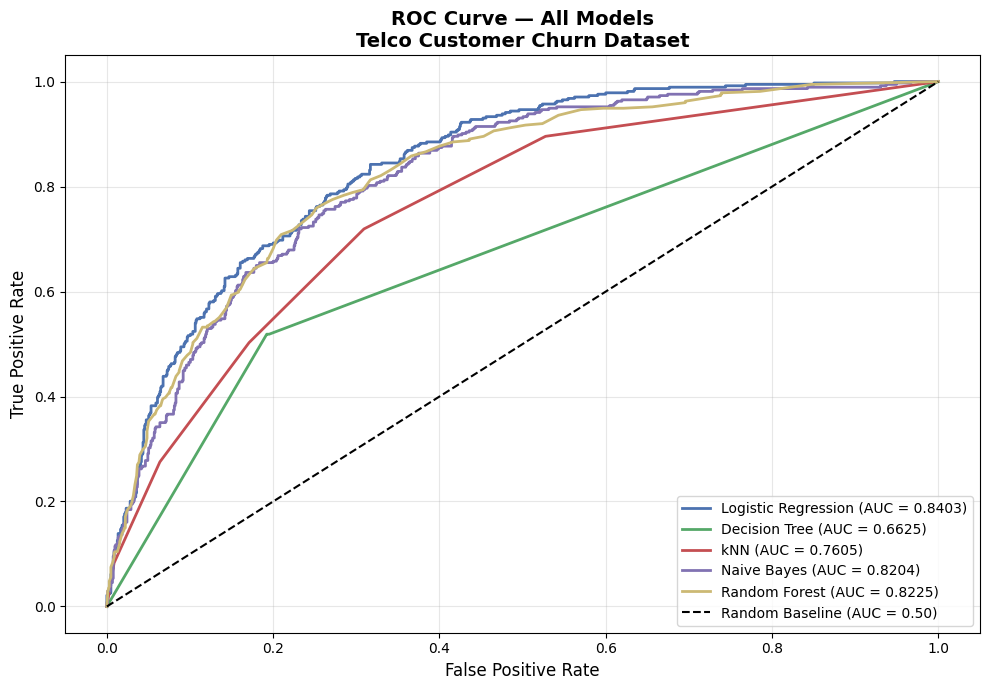

Saved as roc_curve.png


In [24]:
# ROC Curve — All 5 models on one plot
# ROC curve shows True Positive Rate vs False Positive Rate at various thresholds
# AUC (Area Under Curve) — higher is better, 1.0 is perfect, 0.5 is random guessing

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

models_probs = [
    ('Logistic Regression', y_prob_lr),
    ('Decision Tree',       y_prob_dt),
    ('kNN',                 y_prob_knn),
    ('Naive Bayes',         y_prob_nb),
    ('Random Forest',       y_prob_rf),
]

colors_roc = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']

for (name, y_prob), color in zip(models_probs, colors_roc):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'{name} (AUC = {roc_auc:.4f})')

# Random baseline (diagonal line)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Baseline (AUC = 0.50)')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve — All Models\nTelco Customer Churn Dataset', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved as roc_curve.png")

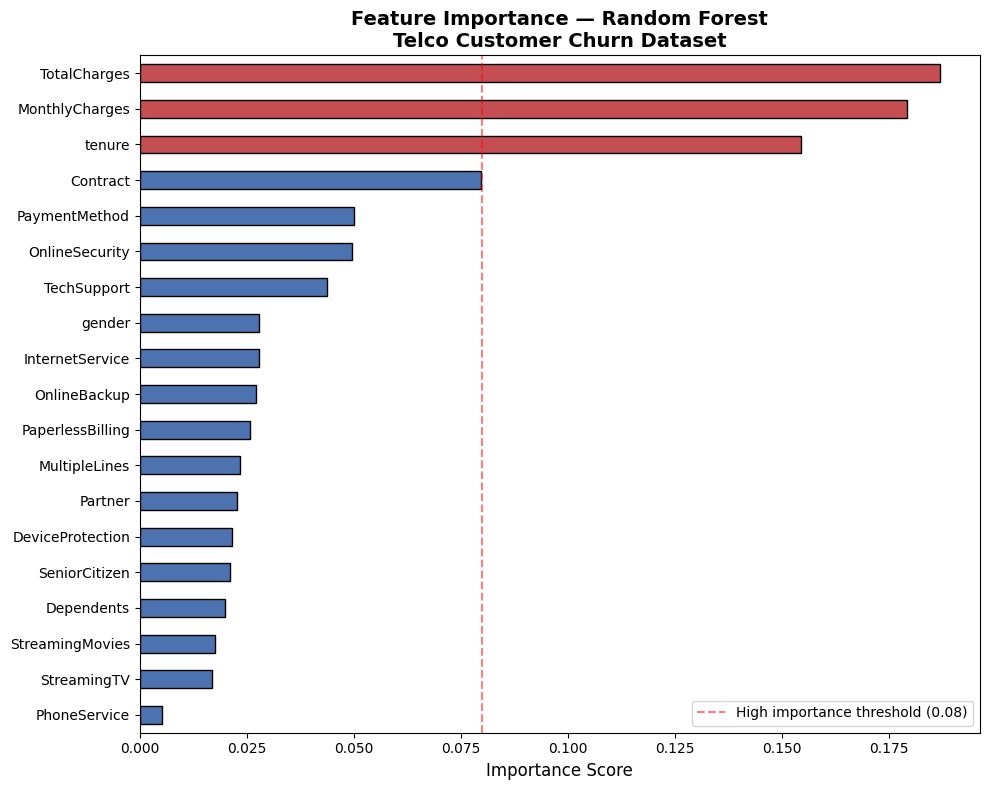


Top 5 most important features:
TotalCharges      0.186841
MonthlyCharges    0.179192
tenure            0.154338
Contract          0.079631
PaymentMethod     0.050095
dtype: float64


In [25]:
# Feature Importance — Random Forest
# Random Forest can rank features by how much they contribute to predictions
# Higher importance = stronger influence on whether a customer churns or not

feature_importance = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importance_sorted = feature_importance.sort_values(ascending=True)

plt.figure(figsize=(10, 8))
colors_fi = ['#C44E52' if v > 0.08 else '#4C72B0' for v in feature_importance_sorted]
feature_importance_sorted.plot(kind='barh', color=colors_fi, edgecolor='black')

plt.xlabel('Importance Score', fontsize=12)
plt.title('Feature Importance — Random Forest\nTelco Customer Churn Dataset',
          fontsize=14, fontweight='bold')
plt.axvline(x=0.08, color='red', linestyle='--', alpha=0.5, label='High importance threshold (0.08)')
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()

print("\nTop 5 most important features:")
print(feature_importance.sort_values(ascending=False).head())

In [27]:
# Classification Report — All Models
# Shows per-class precision, recall, F1 and support
# Gives a complete picture of model performance on both classes separately

from sklearn.metrics import classification_report

model_names = ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'Random Forest']
predictions = [y_pred_lr, y_pred_dt, y_pred_knn, y_pred_nb, y_pred_rf]

for name, y_pred in zip(model_names, predictions):
    print(f"{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
    print()

  Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.87      1035
       Churn       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409


  Decision Tree
              precision    recall  f1-score   support

    No Churn       0.82      0.81      0.81      1035
       Churn       0.49      0.52      0.51       374

    accuracy                           0.73      1409
   macro avg       0.66      0.66      0.66      1409
weighted avg       0.73      0.73      0.73      1409


  kNN
              precision    recall  f1-score   support

    No Churn       0.82      0.83      0.83      1035
       Churn       0.52      0.50      0.51       374

    accuracy                           0.74      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.74     

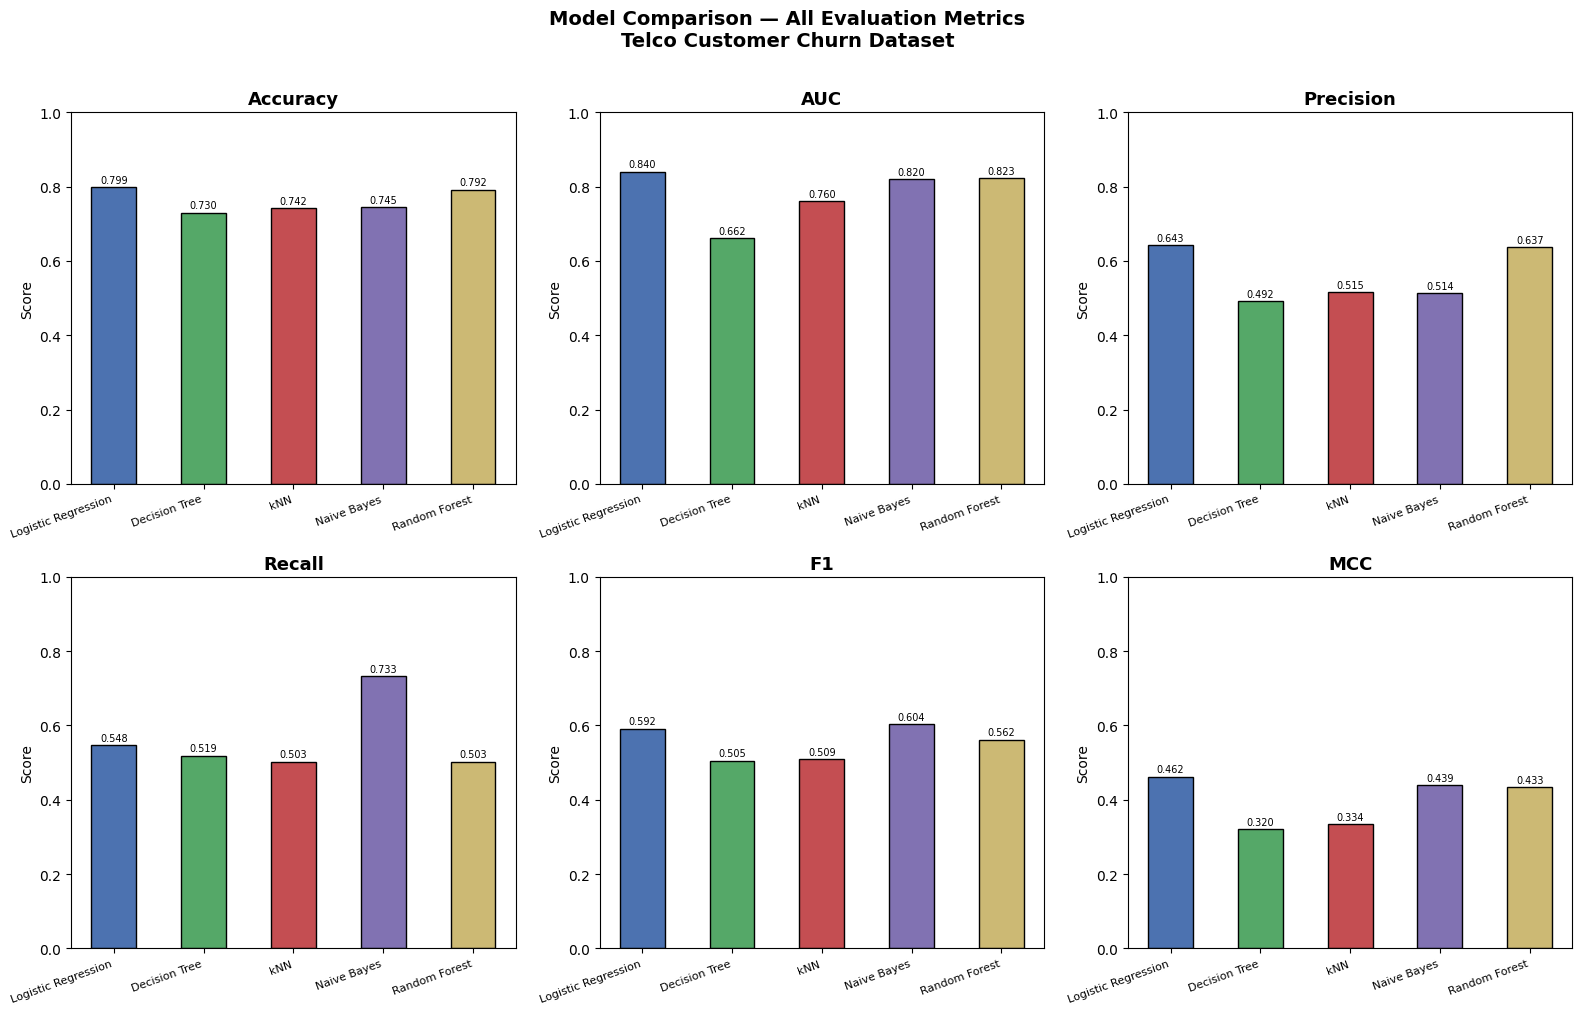

Plot saved as model_comparison.png


In [26]:
# Visualization: Model Comparison across all 6 Evaluation Metrics
# Bar charts for each metric — easy visual comparison across all 5 models

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Compile all results
results = {
    'Model': ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'Random Forest'],
    'Accuracy':  [0.7991, 0.7303, 0.7424, 0.7452, 0.7921],
    'AUC':       [0.8403, 0.6625, 0.7605, 0.8204, 0.8225],
    'Precision': [0.6426, 0.4924, 0.5151, 0.5141, 0.6373],
    'Recall':    [0.5481, 0.5187, 0.5027, 0.7326, 0.5027],
    'F1':        [0.5916, 0.5052, 0.5088, 0.6042, 0.5620],
    'MCC':       [0.4621, 0.3202, 0.3343, 0.4392, 0.4334],
}

results_df = pd.DataFrame(results).set_index('Model')

# Plot
metrics = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    bars = ax.bar(results_df.index, results_df[metric],
                  color=colors, edgecolor='black', width=0.5)
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_ylim(0, 1.0)
    ax.set_xticks(range(len(results_df.index)))  # fix for UserWarning
    ax.set_xticklabels(results_df.index, rotation=20, ha='right', fontsize=8)
    ax.set_ylabel('Score')
    # Add value labels on top of each bar
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=7)

plt.suptitle('Model Comparison — All Evaluation Metrics\nTelco Customer Churn Dataset',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('model_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print("Plot saved as model_comparison.png")

In [31]:
# Save requirements.txt — lists all libraries used in this notebook
requirements = """pandas
numpy
scikit-learn
matplotlib
joblib
"""

with open('/content/drive/MyDrive/Colab Notebooks/ML/Assignment-2/requirements.txt', 'w') as f:
    f.write(requirements)

print("requirements.txt updated!")

requirements.txt updated!


In [29]:
# Save test_data.csv — first 100 rows of test set with actual Churn labels
# This allows the model to be tested independently without the full dataset

test_sample = X_test.copy()
test_sample['Churn'] = y_test.values

test_sample.head(100).to_csv(
    '/content/drive/MyDrive/Colab Notebooks/ML/Assignment-2/test_data.csv',
    index=False
)

print(f"test_data.csv saved — {test_sample.head(100).shape[0]} rows, {test_sample.shape[1]} columns")

test_data.csv saved — 100 rows, 20 columns


In [30]:
# Save all trained models as .joblib files for GitHub submission
import joblib
import os

# Create model folder in Drive
model_path = '/content/drive/MyDrive/Colab Notebooks/ML/Assignment-2/model/'
os.makedirs(model_path, exist_ok=True)

# Save each model
joblib.dump(lr_model,  model_path + 'logistic_regression.joblib')
joblib.dump(dt_model,  model_path + 'decision_tree.joblib')
joblib.dump(knn_model, model_path + 'knn.joblib')
joblib.dump(nb_model,  model_path + 'gaussian_nb.joblib')
joblib.dump(rf_model,  model_path + 'random_forest.joblib')

print("All 5 models saved to Drive/model/ folder:")
for f in os.listdir(model_path):
    print(f"  {f}")

All 5 models saved to Drive/model/ folder:
  logistic_regression.joblib
  decision_tree.joblib
  knn.joblib
  gaussian_nb.joblib
  random_forest.joblib
